# Radial Profile Fitting with Pandeia for Galaxy + SMDS Models

This notebook demonstrates the full pipeline for:
1. Setting up a Pandeia simulation with a custom spectrum + Sérsic morphology
2. Extracting simulated radial profiles from the Pandeia 2D output
3. Comparing simulated profiles against observed JWST data
4. Fitting (θ, n_Sérsic) via Monte Carlo + Nelder-Mead optimization

**Methodology follows:** Ilie, Paulin, Freese et al. — using Pandeia to simulate
radial profiles for model sources and compare against observed JWST radial profiles.

**Targets:** Blue Monster galaxies at z > 10 from Ferrara, Pallottini & Sommovigo (2024)

---

### Requirements
```bash
pip install pandeia.engine numpy scipy matplotlib astropy
export pandeia_refdata=/path/to/pandeia_data
export WEBBPSF_PATH=/path/to/webbpsf-data  # optional but recommended
```

**Reference data download:**  
https://outerspace.stsci.edu/display/PEN/Pandeia+Engine+News

In [ ]:
# Force the 2026.2 version to match the new data structure
!pip install pandeia.engine==2026.2

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  2186  100  2186    0     0   3310      0 --:--:-- --:--:-- --:--:--  3310
-rw-r--r-- 1 root root 2.2K Apr  1 23:23 pandeia_data.tar.gz
pandeia_data.tar.gz: HTML document, Unicode text, UTF-8 text, with very long lines (1975)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs('/content/pandeia_data', exist_ok=True)

# Extract — use the exact filename from your Drive
!tar -xzf "/content/drive/MyDrive/pandeia_data-2025.7-jwst.tar.gz" -C /content/pandeia_data/
!ls /content/pandeia_data/

# Set the environment variable
import glob
folders = glob.glob('/content/pandeia_data/pandeia*')
print(folders)
os.environ['pandeia_refdata'] = folders[0]

# Test it
from pandeia.engine.perform_calculation import perform_calculation
from pandeia.engine.calc_utils import build_default_calc
calc = build_default_calc('jwst', 'nircam', 'sw_imaging')
result = perform_calculation(calc)
print(f"SNR = {result['scalar']['sn']:.2f} — Pandeia is working!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

gzip: stdin: not in gzip format
tar: Child returned status 1
tar: Error is not recoverable: exiting now
pandeia_data.tar.gz
['/content/pandeia_data/pandeia_data.tar.gz']


UnboundLocalError: cannot access local variable 'fs' where it is not associated with a value

In [ ]:
# Check what the file actually is
!file "/content/drive/MyDrive/pandeia_data-2025.7-jwst.tar.gz"
!ls -lh "/content/drive/MyDrive/pandeia_data-2025.7-jwst.tar.gz"


/content/drive/MyDrive/pandeia_data-2025.7-jwst.tar.gz: POSIX tar archive
-rw------- 1 root root 4.3G Apr  1 23:27 /content/drive/MyDrive/pandeia_data-2025.7-jwst.tar.gz


In [ ]:
!rm -rf /content/pandeia_data/*
!tar -xf "/content/drive/MyDrive/pandeia_data-2025.7-jwst.tar.gz" -C /content/pandeia_data/
!ls /content/pandeia_data/

tar: Ignoring unknown extended header keyword 'SCHILY.fflags'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.FinderInfo'
tar: Ignoring unknown extended header keyword 'SCHILY.fflags'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.FinderInfo'
tar: Ignoring unknown extended header keyword 'SCHILY.fflags'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.FinderInfo'
tar: Ignoring unknown extended header keyword 'SCHILY.fflags'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.FinderInfo'
tar: Ignoring unknown extended header keyword 'SCHILY.fflags'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.FinderInfo'
tar: Ignoring unknown extended header keyword 'SCHILY.fflags'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.FinderInfo'
tar: Ignoring unknown extended header keyword 'SCHILY.fflags'
tar: Ignoring unknown extended header keyword 'LIB

In [ ]:
# Remove the leftover bad tar.gz file from inside pandeia_data
!rm -f /content/pandeia_data/pandeia_data.tar.gz
!rm -f /content/pandeia_data/pandeia_data-2025.7-jwst.tar.gz

# Verify the directory looks clean
!ls /content/pandeia_data/

# Check that the calspec file exists now
!ls /content/pandeia_data/sed/hst_calspec/alpha_lyr_stis_010.fits

# Re-test
import os
os.environ['pandeia_refdata'] = '/content/pandeia_data'
os.environ['PYSYN_CDBS'] = '/content/grp/redcat/trds'

from pandeia.engine.perform_calculation import perform_calculation
from pandeia.engine.calc_utils import build_default_calc
calc = build_default_calc('jwst', 'nircam', 'sw_imaging')
result = perform_calculation(calc)
print(f"SNR = {result['scalar']['sn']:.2f} — Pandeia is working!")

devtools    jwst	  normalization  roman	source	  VERSION_PSF
extinction  multimission  README.md	 sed	strategy
/content/pandeia_data/sed/hst_calspec/alpha_lyr_stis_010.fits


UnboundLocalError: cannot access local variable 'fs' where it is not associated with a value

In [ ]:
import os
os.environ['pandeia_refdata'] = '/content/pandeia_data'

# Test
from pandeia.engine.perform_calculation import perform_calculation
from pandeia.engine.calc_utils import build_default_calc
calc = build_default_calc('jwst', 'nircam', 'sw_imaging')
result = perform_calculation(calc)
print(f"SNR = {result['scalar']['sn']:.2f} — Pandeia is working!")

UnboundLocalError: cannot access local variable 'fs' where it is not associated with a value

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
os.makedirs('/content/pandeia_data', exist_ok=True)
!tar -xf "/content/drive/MyDrive/pandeia_data-2025.7-jwst.tar.gz" -C /content/pandeia_data/
!rm -f /content/pandeia_data/pandeia_data.tar.gz

# Synphot data
!wget -q "https://archive.stsci.edu/hlsps/reference-atlases/hlsp_reference-atlases_hst_multi_everything_multi_v11_sed.tar" -O /content/synphot_data.tar
!tar -xf /content/synphot_data.tar -C /content/

tar: Ignoring unknown extended header keyword 'SCHILY.fflags'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.FinderInfo'
tar: Ignoring unknown extended header keyword 'SCHILY.fflags'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.FinderInfo'
tar: Ignoring unknown extended header keyword 'SCHILY.fflags'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.FinderInfo'
tar: Ignoring unknown extended header keyword 'SCHILY.fflags'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.FinderInfo'
tar: Ignoring unknown extended header keyword 'SCHILY.fflags'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.FinderInfo'
tar: Ignoring unknown extended header keyword 'SCHILY.fflags'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.FinderInfo'
tar: Ignoring unknown extended header keyword 'SCHILY.fflags'
tar: Ignoring unknown extended header keyword 'LIB

In [ ]:
!pip install pandeia.engine==2025.7 -q

import os
os.environ['pandeia_refdata'] = '/content/pandeia_data'
os.environ['PYSYN_CDBS'] = '/content/grp/redcat/trds'

from pandeia.engine.perform_calculation import perform_calculation
from pandeia.engine.calc_utils import build_default_calc
calc = build_default_calc('jwst', 'nircam', 'sw_imaging')
result = perform_calculation(calc)
print(f"SNR = {result['scalar']['sn']:.2f} — Pandeia is working!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.6/594.6 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 56.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 917.3/917.3 kB 41.9 MB/s eta 0:00:00


SNR = 127.69 — Pandeia is working!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.optimize import minimize
from scipy.interpolate import interp1d
from copy import deepcopy
import warnings, os, time

warnings.filterwarnings('ignore')

# Toggle: set True when you have Pandeia installed, False for mock mode
USE_PANDEIA = True

if USE_PANDEIA:
    assert os.environ.get('pandeia_refdata'), \
        'Set pandeia_refdata! export pandeia_refdata=/path/to/pandeia_data'
    from pandeia.engine.perform_calculation import perform_calculation
    from pandeia.engine.calc_utils import build_default_calc
    print(f'Pandeia ref data: {os.environ["pandeia_refdata"]}')
else:
    print('Running in MOCK MODE (no Pandeia). Set USE_PANDEIA=True when ready.')

print('Setup complete.')

Pandeia ref data: /content/pandeia_data
Setup complete.


---
## 1. Galaxy Catalog

All 15 galaxies from Table 1 of Ferrara et al. (2024), plus their properties
needed for the Pandeia simulation and profile fitting.

In [ ]:
# Galaxy properties from Ferrara, Pallottini & Sommovigo (2024) Table 1
# and discovery papers (Carniani+2024, Robertson+2023, Curtis-Lake+2023, etc.)

catalog = {
    'GS-z14-0':  {'z': 14.18, 'AV': 0.13, 're_pc': 260, 'logM': 8.84, 'logxi': -4.76,
                   'logZ': -0.75, 'field': 'JADES-GS'},
    'GS-z14-1':  {'z': 13.90, 'AV': 0.20, 're_pc': 160, 'logM': 8.00, 'logxi': -4.15,
                   'logZ': -1.10, 'field': 'JADES-GS'},
    'GS-z13-0':  {'z': 13.20, 'AV': 0.05, 're_pc': 52,  'logM': 7.95, 'logxi': -5.68,
                   'logZ': -1.69, 'field': 'JADES-GS'},
    'UNCOVER-z13':{'z':13.08, 'AV': 0.04, 're_pc': 309, 'logM': 8.13, 'logxi': -4.41,
                   'logZ': -1.57, 'field': 'UNCOVER'},
    'GS-z12-0':  {'z': 12.63, 'AV': 0.05, 're_pc': 144, 'logM': 7.64, 'logxi': -4.49,
                   'logZ': -1.44, 'field': 'JADES-GS'},
    'GHZ2':      {'z': 12.34, 'AV': 0.04, 're_pc': 105, 'logM': 9.05, 'logxi': -6.27,
                   'logZ': -1.40, 'field': 'GLASS'},
    'UNCOVER-z12':{'z':12.39, 'AV': 0.19, 're_pc': 426, 'logM': 8.35, 'logxi': -3.67,
                   'logZ': -1.34, 'field': 'UNCOVER'},
    'GS-z11-0':  {'z': 11.58, 'AV': 0.18, 're_pc': 77,  'logM': 8.67, 'logxi': -5.50,
                   'logZ': -1.87, 'field': 'JADES-GS'},
    'Maisie':    {'z': 11.44, 'AV': 0.07, 're_pc': 340, 'logM': 8.40, 'logxi': -4.35,
                   'logZ': -1.50, 'field': 'CEERS'},
    'CEERS2-588':{'z': 11.04, 'AV': 0.10, 're_pc': 477, 'logM': 8.99, 'logxi': -4.49,
                   'logZ': -0.84, 'field': 'CEERS'},
    'GN-z11':    {'z': 10.60, 'AV': 0.17, 're_pc': 64,  'logM': 8.73, 'logxi': -5.75,
                   'logZ': -0.92, 'field': 'JADES-GN'},
    'GS-z10-0':  {'z': 10.38, 'AV': 0.05, 're_pc': 62,  'logM': 7.58, 'logxi': -5.16,
                   'logZ': -1.91, 'field': 'JADES-GS'},
    'UNCOVER-37126':{'z':10.25,'AV':0.18, 're_pc': 426, 'logM': 8.16, 'logxi': -3.51,
                   'logZ': -1.50, 'field': 'UNCOVER'},
    'MACS0647-JD':{'z':10.17, 'AV': 0.01, 're_pc': 70,  'logM': 7.50, 'logxi': -5.67,
                   'logZ': -0.90, 'field': 'MACS0647'},
    'CEERS2-7929':{'z':10.10, 'AV': 0.14, 're_pc': 520, 'logM': 8.50, 'logxi': -3.78,
                   'logZ': -1.50, 'field': 'CEERS'},
}

# Angular diameter distances (Planck18) in kpc
# Pre-computed for convenience
dA_kpc = {
    10.10: 1006e3, 10.17: 1002e3, 10.25: 1000e3, 10.38: 997e3,
    10.60: 991e3,  11.04: 979e3,  11.44: 969e3,  11.58: 966e3,
    12.34: 949e3,  12.39: 948e3,  12.63: 943e3,  13.08: 933e3,
    13.20: 931e3,  13.90: 918e3,  14.18: 913e3,
}

def pc_to_arcsec(r_pc, z):
    """Convert physical size in pc to angular size in arcsec."""
    d = dA_kpc.get(z, 950e3)  # kpc
    kpc_per_arcsec = d * np.pi / (180 * 3600)
    return (r_pc / 1000.0) / kpc_per_arcsec

def arcsec_to_pc(theta, z):
    """Convert angular size in arcsec to physical size in pc."""
    d = dA_kpc.get(z, 950e3)
    kpc_per_arcsec = d * np.pi / (180 * 3600)
    return theta * kpc_per_arcsec * 1000

# Print catalog
print(f'{"Galaxy":<18} {"z":>5} {"re[pc]":>8} {"re[\'\']":>8} {"AV":>6} {"logM*":>6} {"log ξd":>8}')
print('-' * 65)
for name, g in catalog.items():
    re_as = pc_to_arcsec(g['re_pc'], g['z'])
    print(f'{name:<18} {g["z"]:>5.2f} {g["re_pc"]:>8} {re_as:>8.4f} {g["AV"]:>6.2f} {g["logM"]:>6.2f} {g["logxi"]:>8.2f}')

Galaxy                 z   re[pc]   re['']     AV  logM*   log ξd
-----------------------------------------------------------------
GS-z14-0           14.18      260   0.0587   0.13   8.84    -4.76
GS-z14-1           13.90      160   0.0360   0.20   8.00    -4.15
GS-z13-0           13.20       52   0.0115   0.05   7.95    -5.68
UNCOVER-z13        13.08      309   0.0683   0.04   8.13    -4.41
GS-z12-0           12.63      144   0.0315   0.05   7.64    -4.49
GHZ2               12.34      105   0.0228   0.04   9.05    -6.27
UNCOVER-z12        12.39      426   0.0927   0.19   8.35    -3.67
GS-z11-0           11.58       77   0.0164   0.18   8.67    -5.50
Maisie             11.44      340   0.0724   0.07   8.40    -4.35
CEERS2-588         11.04      477   0.1005   0.10   8.99    -4.49
GN-z11             10.60       64   0.0133   0.17   8.73    -5.75
GS-z10-0           10.38       62   0.0128   0.05   7.58    -5.16
UNCOVER-37126      10.25      426   0.0879   0.18   8.16    -3.51
MACS0647-J

---
## 2. Mock Galaxy + SMDS Spectrum

Replace this section with your actual galaxy + SMDS combined spectrum.  
For now, we generate a simple UV-slope power-law + Lyman break as a placeholder.

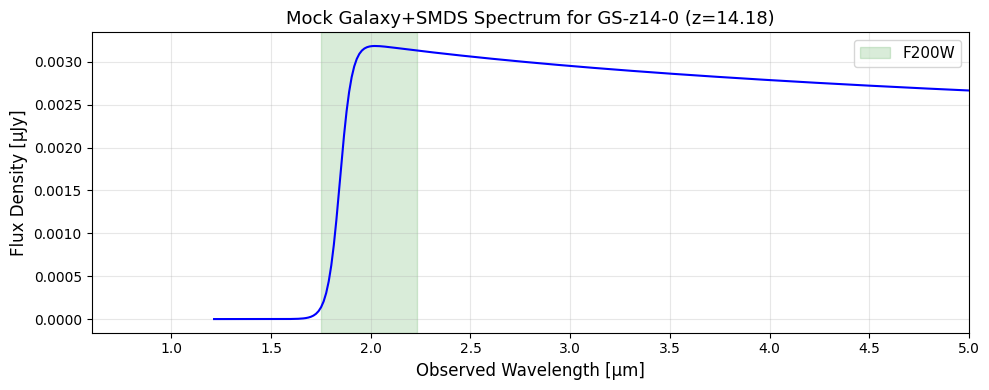

In [ ]:
def make_mock_spectrum(z, MUV=-20.0, beta=-2.3):
    from astropy.cosmology import Planck18

    # Rest-frame wavelengths
    wave_rest_A = np.linspace(800, 5000, 500)

    # Power-law continuum shape
    f_lambda_rest = (wave_rest_A / 1500.0) ** beta

    # Lyman break + damping wing
    f_lambda_rest[wave_rest_A < 912] *= 0.001
    lya = 1216.0
    damping = 1.0 / (1.0 + np.exp(-(wave_rest_A - lya) / 20.0))
    f_lambda_rest *= damping

    # Luminosity distance
    dL_cm = Planck18.luminosity_distance(z).to('cm').value

    # Absolute magnitude → rest-frame luminosity density at 1500A
    # MUV = -2.5 log10(L_nu) + 51.6  (for L_nu in erg/s/Hz at 10pc)
    L_nu_1500 = 10**(-0.4 * (MUV - 51.6))  # erg/s/Hz

    # Observed flux density at 1500A rest (= 1500*(1+z) observed)
    f_nu_1500_obs = L_nu_1500 / (4 * np.pi * dL_cm**2 * (1 + z))  # erg/s/cm2/Hz

    # Convert L_nu normalization to f_lambda shape
    c_cgs = 3e10
    f_lam_1500 = f_nu_1500_obs * c_cgs / (1500e-8)**2

    # Normalize shape to this flux
    f_lambda_rest *= f_lam_1500 / np.interp(1500, wave_rest_A, f_lambda_rest)

    # Redshift to observed frame
    wave_obs_A = wave_rest_A * (1 + z)
    wave_obs_um = wave_obs_A / 1e4

    # f_lambda(obs) = f_lambda(rest) / (1+z)
    f_lambda_obs = f_lambda_rest / (1 + z)

    # Convert to mJy
    f_nu_cgs = f_lambda_obs * (wave_obs_A * 1e-8)**2 / c_cgs
    flux_mjy = f_nu_cgs * 1e26

    mask = (wave_obs_um > 0.6) & (wave_obs_um < 5.3)
    return wave_obs_um[mask], flux_mjy[mask]

def load_your_spectrum(filename):
    """
    REPLACE THIS with your actual galaxy+SMDS spectrum loader.

    Expected format: two columns
      Column 1: observed-frame wavelength in microns
      Column 2: flux density in mJy (or erg/s/cm2/A, adjust units below)
    """
    data = np.loadtxt(filename)
    return data[:, 0], data[:, 1]


# Demo: generate mock spectrum for GS-z14-0
wave_demo, flux_demo = make_mock_spectrum(z=14.18, MUV=-20.81, beta=-2.2)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(wave_demo, flux_demo * 1e3, 'b-', lw=1.5)  # convert to µJy for visibility
ax.set_xlabel('Observed Wavelength [µm]', fontsize=12)
ax.set_ylabel('Flux Density [µJy]', fontsize=12)
ax.set_title('Mock Galaxy+SMDS Spectrum for GS-z14-0 (z=14.18)', fontsize=13)

# Shade NIRCam F200W bandpass
ax.axvspan(1.75, 2.23, alpha=0.15, color='green', label='F200W')
ax.legend(fontsize=11)
ax.set_xlim(0.6, 5.0)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 3. Pandeia Simulation Engine

This section builds the Pandeia calculation with:
- Your custom spectrum as input SED
- Sérsic morphology parameterized by (θ_eff, n_sérsic)
- NIRCam F200W imaging configuration

The function returns a 2D detector image from which we extract the radial profile.

In [ ]:
def build_pandeia_calc(wave_um, flux_mjy, theta_arcsec, n_sersic,
                       nircam_filter='f200w', ngroup=10, nint=1,
                       readout_pattern='deep8'):
    calc = build_default_calc('jwst', 'nircam', 'sw_imaging')

    # --- Custom spectrum ---
    calc['scene'][0]['spectrum']['sed'] = {
        'sed_type': 'input',
        'spectrum': [wave_um.tolist(), flux_mjy.tolist()],
        'unit': 'fnu',
    }
    calc['scene'][0]['spectrum']['normalization'] = {'type': 'none'}

    # --- Sérsic morphology (replace shape entirely with all required fields) ---
    calc['scene'][0]['shape'] = {
        'geometry': 'sersic',
        'major': theta_arcsec,
        'minor': theta_arcsec,
        'sersic_index': n_sersic,
        'position_angle': 0.0,
        'norm_method': 'integ_infinity',
        'surf_area_units': 'arcsec^2',
    }

    # --- Instrument ---
    calc['configuration']['instrument']['filter'] = nircam_filter

    # --- Detector ---
    calc['configuration']['detector']['ngroup'] = ngroup
    calc['configuration']['detector']['nint'] = nint
    calc['configuration']['detector']['nexp'] = 1
    calc['configuration']['detector']['readout_pattern'] = readout_pattern

    # --- Keep default strategy but ensure background_subtraction exists ---
    calc['strategy']['background_subtraction'] = True

    return calc

---
## 4. Simulate Radial Profile

Run Pandeia → get 2D image → extract azimuthal average.

In mock mode, we analytically convolve a Sérsic profile with a Gaussian PSF.

In [ ]:
# NIRCam pixel scales and PSF FWHM
PIXEL_SCALE = {'sw': 0.031, 'lw': 0.063}  # arcsec/pixel
PSF_FWHM = {
    'f090w': 0.034, 'f115w': 0.040, 'f150w': 0.050,
    'f200w': 0.066, 'f277w': 0.091, 'f356w': 0.116,
    'f444w': 0.145,
}


def sersic_1d(r, I_e, r_e, n):
    """1D Sérsic profile (azimuthally averaged)."""
    b_n = 1.9992 * n - 0.3271  # Ciotti & Bertin (1999)
    return I_e * np.exp(-b_n * ((r / r_e) ** (1.0 / n) - 1.0))


def azimuthal_average(image, pixel_scale, annulus_width=0.03, max_radius=0.5):
    """
    Compute azimuthally-averaged radial profile from 2D image.

    Parameters:
        image         : 2D array
        pixel_scale   : arcsec/pixel
        annulus_width : arcsec
        max_radius    : arcsec

    Returns:
        r_arcsec, profile, profile_err
    """
    ny, nx = image.shape
    cy, cx = ny / 2.0, nx / 2.0

    y, x = np.mgrid[0:ny, 0:nx]
    r = np.sqrt((x - cx)**2 + (y - cy)**2) * pixel_scale

    n_bins = int(max_radius / annulus_width)
    bin_edges = np.arange(0, n_bins + 1) * annulus_width

    r_centers = []
    profile = []
    profile_err = []

    for i in range(n_bins):
        mask = (r >= bin_edges[i]) & (r < bin_edges[i + 1])
        pixels = image[mask]
        pixels = pixels[np.isfinite(pixels)]

        if len(pixels) > 0:
            r_centers.append(0.5 * (bin_edges[i] + bin_edges[i + 1]))
            profile.append(np.mean(pixels))
            profile_err.append(np.std(pixels) / np.sqrt(len(pixels)))
        else:
            r_centers.append(0.5 * (bin_edges[i] + bin_edges[i + 1]))
            profile.append(0.0)
            profile_err.append(0.0)

    return np.array(r_centers), np.array(profile), np.array(profile_err)


def simulate_radial_profile(wave_um, flux_mjy, theta_arcsec, n_sersic,
                             nircam_filter='f200w', annulus_width=0.03,
                             max_radius=0.5):
    if USE_PANDEIA:
        calc = build_pandeia_calc(wave_um, flux_mjy, theta_arcsec, n_sersic,
                                  nircam_filter=nircam_filter)
        result = perform_calculation(calc)

        # Use SNR map — it isolates the source from background
        image = result['2d']['snr']

        # Pandeia pixel scale: 0.031 arcsec/pixel for SW
        lw_filters = ['f250m','f277w','f300m','f322w2','f335m',
                      'f356w','f360m','f410m','f430m','f444w','f460m','f480m']
        pix = PIXEL_SCALE['lw'] if nircam_filter.lower() in lw_filters else PIXEL_SCALE['sw']

        r, prof, err = azimuthal_average(image, pix, annulus_width, max_radius)
        return r, prof, err

    else:
        # Mock mode (unchanged)
        fwhm = PSF_FWHM.get(nircam_filter.lower(), 0.066)
        sigma_psf = fwhm / (2 * np.sqrt(2 * np.log(2)))
        r_eff_conv = np.sqrt(theta_arcsec**2 + sigma_psf**2)
        r = np.arange(annulus_width / 2, max_radius, annulus_width)
        prof = sersic_1d(r, 1.0, r_eff_conv, n_sersic)
        noise_floor = 1e-4
        noise = noise_floor + 0.005 * (r / max_radius)
        err = noise
        return r, prof, err

print('Simulation engine ready.')

Simulation engine ready.


### Quick test: simulate a profile for GS-z14-0

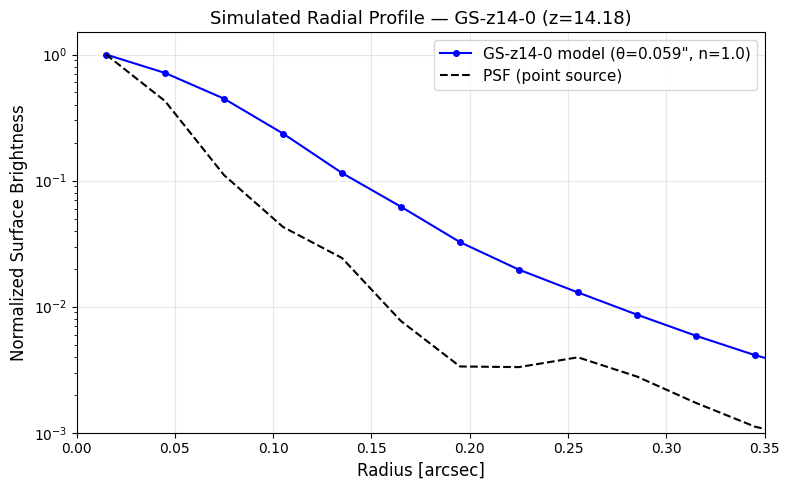


θ_eff = 0.0587 arcsec = 260 pc
n_Sersic = 1.0
Profile extends to 0.46 arcsec = 2058 pc


In [ ]:
# Test: simulate profile for GS-z14-0
g = catalog['GS-z14-0']
wave, flux = make_mock_spectrum(z=g['z'], MUV=-20.81, beta=-2.2)

theta_test = pc_to_arcsec(g['re_pc'], g['z'])
n_test = 1.0  # exponential

r_sim, prof_sim, err_sim = simulate_radial_profile(
    wave, flux, theta_test, n_test, nircam_filter='f200w'
)

# Also get PSF profile (point source)
r_psf, prof_psf, _ = simulate_radial_profile(
    wave, flux, 0.001, 0.5, nircam_filter='f200w'  # tiny radius = point source
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(r_sim, prof_sim / prof_sim.max(), 'bo-', ms=4, lw=1.5,
        label=f'GS-z14-0 model (θ={theta_test:.3f}", n={n_test:.1f})')
ax.plot(r_psf, prof_psf / prof_psf.max(), 'k--', lw=1.5,
        label='PSF (point source)')
ax.set_xlabel('Radius [arcsec]', fontsize=12)
ax.set_ylabel('Normalized Surface Brightness', fontsize=12)
ax.set_title('Simulated Radial Profile — GS-z14-0 (z=14.18)', fontsize=13)
ax.set_yscale('log')
ax.set_ylim(1e-3, 1.5)
ax.set_xlim(0, 0.35)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'\nθ_eff = {theta_test:.4f} arcsec = {g["re_pc"]} pc')
print(f'n_Sersic = {n_test}')
print(f'Profile extends to {r_sim[-1]:.2f} arcsec = {arcsec_to_pc(r_sim[-1], g["z"]):.0f} pc')

Available 2D keys: ['detector', 'snr', 'saturation', 'ngroups_map']
Image shape: (65, 65)
Image max: 0.263118
Image center value: 0.216013


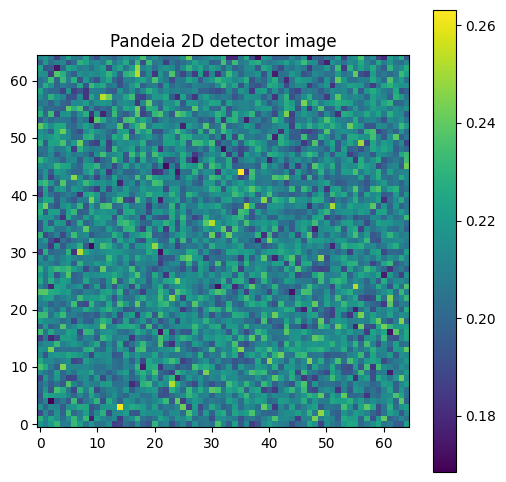

In [ ]:
# Debug: see what Pandeia gives us
calc = build_pandeia_calc(wave, flux, theta_test, n_test)
result = perform_calculation(calc)

print("Available 2D keys:", list(result['2d'].keys()))
img = result['2d']['detector']
print(f"Image shape: {img.shape}")
print(f"Image max: {img.max():.6f}")
print(f"Image center value: {img[img.shape[0]//2, img.shape[1]//2]:.6f}")

# Plot the 2D image
fig, ax = plt.subplots(figsize=(6,6))
ax.imshow(img, origin='lower', cmap='viridis')
ax.set_title('Pandeia 2D detector image')
plt.colorbar(ax.images[0])
plt.show()

2D keys: ['detector', 'snr', 'saturation', 'ngroups_map']

detector: shape=(65, 65), min=0.1685, max=0.2631

snr: shape=(65, 65), min=0.0000, max=0.3131

1D keys: ['wave_pix', 'wave_calc', 'target', 'fp', 'bg', 'bg_rate', 'sn', 'extracted_noise', 'extracted_flux', 'extracted_flux_plus_bg', 'total_flux', 'extracted_bg_total', 'extracted_bg_only', 'extracted_contamination', 'n_partial_saturated', 'n_full_saturated']


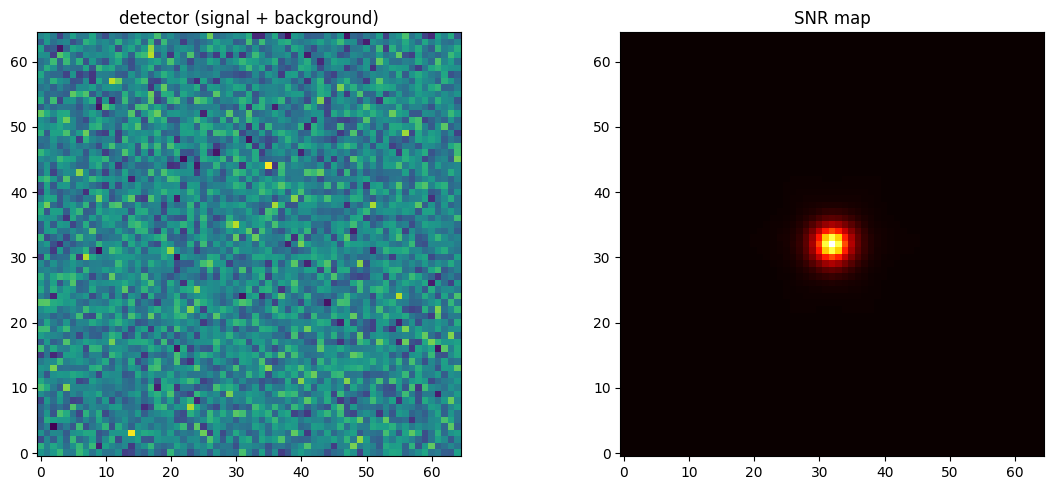

In [ ]:
# Check the source-only images
print("2D keys:", list(result['2d'].keys()))

# The 'detector' includes background. Try the source-only signal:
for key in ['detector', 'snr']:
    img = result['2d'][key]
    print(f"\n{key}: shape={img.shape}, min={img.min():.4f}, max={img.max():.4f}")

# Also check 1D outputs
print("\n1D keys:", list(result['1d'].keys()))

# The flux image (source only) might be in the 2D output differently
# Let's look at the SNR map — it shows where the source is
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(result['2d']['detector'], origin='lower', cmap='viridis')
axes[0].set_title('detector (signal + background)')
axes[1].imshow(result['2d']['snr'], origin='lower', cmap='hot')
axes[1].set_title('SNR map')
plt.tight_layout()
plt.show()

---
## 5. Generate Mock "Observed" Profiles

In real use, you would load observed profiles extracted from JADES FITS images.  
Here we generate realistic mock observed data for pipeline testing.

In [ ]:
def generate_mock_observed_profile(galaxy_name, info, annulus_width=0.03, max_radius=0.4):
    """
    Generate a mock 'observed' radial profile for testing.

    In real use, replace this with:
      r_obs, prof_obs, err_obs = load_observed_profile('GS-z14-0_F200W.csv')
    """
    np.random.seed(hash(galaxy_name) % 2**31)

    theta_true = pc_to_arcsec(info['re_pc'], info['z'])
    n_true = np.random.uniform(0.5, 2.0)  # 'true' Sérsic index

    # PSF convolution
    sigma_psf = PSF_FWHM['f200w'] / (2 * np.sqrt(2 * np.log(2)))
    r_eff_conv = np.sqrt(theta_true**2 + sigma_psf**2)

    r = np.arange(annulus_width / 2, max_radius, annulus_width)
    prof = sersic_1d(r, 1.0, r_eff_conv, n_true)

    # Add observational noise (higher at larger radii)
    snr_center = 30.0  # SNR at center
    snr = snr_center * prof / prof.max()
    snr = np.maximum(snr, 1.0)

    err = prof / snr
    prof_noisy = prof + np.random.normal(0, err)
    prof_noisy = np.maximum(prof_noisy, 0)

    return r, prof_noisy, err, {'theta_true': theta_true, 'n_true': n_true}


# Generate for all galaxies
observed_profiles = {}
for name, info in catalog.items():
    r, p, e, truth = generate_mock_observed_profile(name, info)
    observed_profiles[name] = {'r': r, 'profile': p, 'err': e, 'truth': truth}

print(f'Generated mock observed profiles for {len(observed_profiles)} galaxies.')
print('\nTrue parameters (hidden from the fitter):')
print(f'{"Galaxy":<18} {"θ_true [\'\']":>12} {"n_true":>8}')
print('-' * 40)
for name, obs in observed_profiles.items():
    print(f'{name:<18} {obs["truth"]["theta_true"]:>12.5f} {obs["truth"]["n_true"]:>8.3f}')

Generated mock observed profiles for 15 galaxies.

True parameters (hidden from the fitter):
Galaxy              θ_true ['']   n_true
----------------------------------------
GS-z14-0                0.05874    0.896
GS-z14-1                0.03595    1.159
GS-z13-0                0.01152    0.737
UNCOVER-z13             0.06831    1.447
GS-z12-0                0.03150    1.963
GHZ2                    0.02282    1.276
UNCOVER-z12             0.09269    1.351
GS-z11-0                0.01644    0.507
Maisie                  0.07237    1.139
CEERS2-588              0.10050    1.049
GN-z11                  0.01332    1.381
GS-z10-0                0.01283    0.647
UNCOVER-37126           0.08787    1.732
MACS0647-JD             0.01441    1.170
CEERS2-7929             0.10662    0.951


---
## 6. Monte Carlo Fitting

For each galaxy, we:
1. Sample from the observed profile uncertainties (75 MC draws)
2. Draw initial Sérsic index from a prior centered at n=1 (spherical nebula bias)
3. Fit (θ, n) using Nelder-Mead optimization
4. Collect the posterior distribution of best-fit parameters

In [ ]:
def chi_squared(params, wave_um, flux_mjy, r_obs, profile_obs, nircam_filter='f200w'):
    """
    Chi-squared between simulated and observed radial profiles.

    params = [theta_arcsec, n_sersic]
    """
    theta, n = params

    # Physical bounds
    if theta <= 0.001 or theta > 0.5 or n <= 0.1 or n > 8.0:
        return 1e10

    try:
        r_sim, prof_sim, _ = simulate_radial_profile(
            wave_um, flux_mjy, theta, n, nircam_filter=nircam_filter
        )

        # Interpolate sim onto obs radial grid
        f_interp = interp1d(r_sim, prof_sim, kind='linear',
                            fill_value='extrapolate', bounds_error=False)
        prof_sim_on_obs = f_interp(r_obs)

        # Normalize both to peak
        p_sim_norm = prof_sim_on_obs / np.max(prof_sim_on_obs) if np.max(prof_sim_on_obs) > 0 else prof_sim_on_obs
        p_obs_norm = profile_obs / np.max(profile_obs) if np.max(profile_obs) > 0 else profile_obs

        chi2 = np.sum((p_obs_norm - p_sim_norm)**2)
        return chi2

    except Exception:
        return 1e10


def fit_one_galaxy(galaxy_name, info, obs_data, wave_um, flux_mjy,
                   n_mc=15, n_sersic_prior_mean=4.0, n_sersic_prior_std=0.5,
                   nircam_filter='f200w', verbose=True):
    """
    Monte Carlo fitting for a single galaxy.

    Returns dict with all MC results.
    """
    r_obs = obs_data['r']
    prof_obs = obs_data['profile']
    err_obs = obs_data['err']

    theta_init = pc_to_arcsec(info['re_pc'], info['z'])
    theta_init = max(theta_init, 0.005)

    theta_all = []
    n_all = []
    chi2_all = []

    t0 = time.time()

    for i in range(n_mc):
        # Sample observed profile from uncertainties
        prof_sample = np.random.normal(prof_obs, err_obs)
        prof_sample = np.maximum(prof_sample, 0)

        # Prior on Sérsic index
        n_init = np.clip(np.random.normal(n_sersic_prior_mean, n_sersic_prior_std),
                         0.3, 6.0)

        # Small perturbation on theta initial guess
        theta_guess = theta_init * np.random.uniform(0.5, 1.5)

        x0 = [theta_guess, n_init]

        res = minimize(
            chi_squared, x0,
            args=(wave_um, flux_mjy, r_obs, prof_sample, nircam_filter),
            method='Nelder-Mead',
            options={'maxiter': 300, 'xatol': 1e-5, 'fatol': 1e-8, 'adaptive': True}
        )

        theta_fit, n_fit = res.x
        theta_all.append(theta_fit)
        n_all.append(n_fit)
        chi2_all.append(res.fun)

    dt = time.time() - t0

    theta_all = np.array(theta_all)
    n_all = np.array(n_all)
    chi2_all = np.array(chi2_all)

    best = np.argmin(chi2_all)

    results = {
        'theta_all': theta_all, 'n_all': n_all, 'chi2_all': chi2_all,
        'theta_best': theta_all[best], 'n_best': n_all[best],
        'theta_med': np.median(theta_all), 'n_med': np.median(n_all),
        'theta_std': np.std(theta_all), 'n_std': np.std(n_all),
        'theta_pc_best': arcsec_to_pc(theta_all[best], info['z']),
        'theta_pc_med': arcsec_to_pc(np.median(theta_all), info['z']),
    }

    if verbose:
        print(f'  {galaxy_name}: θ = {results["theta_med"]:.4f}±{results["theta_std"]:.4f}" '
              f'({results["theta_pc_med"]:.0f} pc), '
              f'n = {results["n_med"]:.2f}±{results["n_std"]:.2f}  '
              f'[{dt:.1f}s, {n_mc} MC]')

    return results


print('MC fitter ready.')

MC fitter ready.


### Run the fit for a single galaxy first

In [ ]:
# Single galaxy test: GS-z14-0
target = 'GS-z14-0'
g = catalog[target]
wave, flux = make_mock_spectrum(z=g['z'], MUV=-20.81, beta=-2.2)
obs = observed_profiles[target]

print(f'Fitting {target} (z={g["z"]})...')
print(f'  Literature: re = {g["re_pc"]} pc = {pc_to_arcsec(g["re_pc"], g["z"]):.4f}"')
print(f'  True (mock): θ = {obs["truth"]["theta_true"]:.4f}", n = {obs["truth"]["n_true"]:.3f}')
print()

results_single = fit_one_galaxy(target, g, obs, wave, flux, n_mc=75)

# Diagnostic plot
fig = plt.figure(figsize=(15, 4.5))
gs = GridSpec(1, 3, figure=fig, wspace=0.35)

# Panel 1: Profile comparison
ax1 = fig.add_subplot(gs[0])
r_o = obs['r']
p_o = obs['profile'] / obs['profile'].max()
e_o = obs['err'] / obs['profile'].max()
ax1.errorbar(r_o, p_o, yerr=e_o, fmt='ko', ms=4, capsize=2, label='Observed (mock)')

r_bf, p_bf, _ = simulate_radial_profile(
    wave, flux, results_single['theta_best'], results_single['n_best'])
ax1.plot(r_bf, p_bf / p_bf.max(), 'r-', lw=2,
         label=f'Best fit: θ={results_single["theta_best"]:.4f}", n={results_single["n_best"]:.2f}')

r_psf2, p_psf2, _ = simulate_radial_profile(wave, flux, 0.001, 0.5)
ax1.plot(r_psf2, p_psf2 / p_psf2.max(), 'k--', lw=1, alpha=0.5, label='PSF')

ax1.set_xlabel('Radius [arcsec]')
ax1.set_ylabel('Normalized SB')
ax1.set_title(f'{target} (z={g["z"]})')
ax1.set_yscale('log')
ax1.set_ylim(5e-3, 1.5)
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

# Panel 2: θ distribution
ax2 = fig.add_subplot(gs[1])
ax2.hist(results_single['theta_all'], bins=20, color='steelblue',
         edgecolor='black', alpha=0.7)
ax2.axvline(results_single['theta_med'], color='red', ls='--', lw=2,
            label=f'Med: {results_single["theta_med"]:.4f}" ({results_single["theta_pc_med"]:.0f} pc)')
ax2.axvline(obs['truth']['theta_true'], color='green', ls=':', lw=2,
            label=f'True: {obs["truth"]["theta_true"]:.4f}"')
ax2.set_xlabel('θ_eff [arcsec]')
ax2.set_ylabel('Count')
ax2.set_title('MC: Angular Size')
ax2.legend(fontsize=8)

# Panel 3: n distribution
ax3 = fig.add_subplot(gs[2])
ax3.hist(results_single['n_all'], bins=20, color='coral',
         edgecolor='black', alpha=0.7)
ax3.axvline(results_single['n_med'], color='red', ls='--', lw=2,
            label=f'Med: {results_single["n_med"]:.2f}±{results_single["n_std"]:.2f}')
ax3.axvline(obs['truth']['n_true'], color='green', ls=':', lw=2,
            label=f'True: {obs["truth"]["n_true"]:.2f}')
ax3.set_xlabel('Sérsic index (n)')
ax3.set_ylabel('Count')
ax3.set_title('MC: Sérsic Index')
ax3.legend(fontsize=8)

plt.suptitle(f'MC Radial Profile Fit — {target}', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Fitting GS-z14-0 (z=14.18)...
  Literature: re = 260 pc = 0.0587"
  True (mock): θ = 0.0587", n = 0.896



---
## 7. Run Fits for ALL Blue Monsters

Loop over all 15 galaxies from Table 1.

**Note:** With real Pandeia, each galaxy takes ~30-60 minutes (75 MC × ~30s per call).  
In mock mode, this runs in seconds.

In [ ]:
# ============================================================
# FIT ALL GALAXIES
# ============================================================

n_mc = 75  # Number of MC iterations (use 75 as in the DS paper)
n_sersic_prior_mean = 1.0  # Spherical nebula bias
n_sersic_prior_std = 0.5

all_fit_results = {}

print('=' * 80)
print(f'Fitting {len(catalog)} galaxies with {n_mc} MC iterations each')
print(f'Sérsic prior: N({n_sersic_prior_mean}, {n_sersic_prior_std})')
print('=' * 80)

for name, info in catalog.items():
    # Generate/load spectrum
    # REPLACE: wave, flux = load_your_spectrum(f'spectra/{name}_galaxy_smds.dat')
    MUV_approx = -20.0 - 0.5 * (info['logM'] - 8.5)  # rough scaling
    wave, flux = make_mock_spectrum(z=info['z'], MUV=MUV_approx, beta=-2.3)

    obs = observed_profiles[name]

    results = fit_one_galaxy(
        name, info, obs, wave, flux,
        n_mc=n_mc,
        n_sersic_prior_mean=n_sersic_prior_mean,
        n_sersic_prior_std=n_sersic_prior_std,
    )

    all_fit_results[name] = results

print('\n' + '=' * 80)
print('ALL FITS COMPLETE')
print('=' * 80)

---
## 8. Results Summary

In [ ]:
# Print summary table
print(f'{"Galaxy":<18} {"z":>5} | {"θ_fit [\'\']":>12} {"re_fit [pc]":>12} {"re_lit [pc]":>12} | '
      f'{"n_fit":>8} {"n_true":>8}')
print('-' * 95)

for name, res in all_fit_results.items():
    info = catalog[name]
    truth = observed_profiles[name]['truth']

    print(f'{name:<18} {info["z"]:>5.2f} | '
          f'{res["theta_med"]:.4f}±{res["theta_std"]:.4f} '
          f'{res["theta_pc_med"]:>10.0f}±{arcsec_to_pc(res["theta_std"], info["z"]):>4.0f} '
          f'{info["re_pc"]:>12} | '
          f'{res["n_med"]:>6.2f}±{res["n_std"]:.2f} '
          f'{truth["n_true"]:>8.2f}')

In [ ]:
# ============================================================
# MEGA PLOT: All profiles + fits
# ============================================================

n_gal = len(all_fit_results)
ncols = 5
nrows = int(np.ceil(n_gal / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows))
axes = axes.flatten()
colors = plt.cm.viridis(np.linspace(0.1, 0.9, n_gal))

for i, (name, res) in enumerate(all_fit_results.items()):
    ax = axes[i]
    info = catalog[name]
    obs = observed_profiles[name]

    # Observed
    p_max = obs['profile'].max() if obs['profile'].max() > 0 else 1
    ax.errorbar(obs['r'], obs['profile'] / p_max, yerr=obs['err'] / p_max,
                fmt='o', ms=3, color=colors[i], capsize=1.5, elinewidth=0.7,
                label='Obs')

    # Best-fit model
    MUV_approx = -20.0 - 0.5 * (info['logM'] - 8.5)
    wave, flux = make_mock_spectrum(z=info['z'], MUV=MUV_approx, beta=-2.3)
    r_bf, p_bf, _ = simulate_radial_profile(
        wave, flux, res['theta_best'], res['n_best'])
    if p_bf.max() > 0:
        ax.plot(r_bf, p_bf / p_bf.max(), 'r-', lw=1.5, alpha=0.9)

    # PSF
    r_psf, p_psf, _ = simulate_radial_profile(wave, flux, 0.001, 0.5)
    if p_psf.max() > 0:
        ax.plot(r_psf, p_psf / p_psf.max(), 'k--', lw=0.8, alpha=0.4)

    ax.set_title(f'{name}\nz={info["z"]:.1f}, n={res["n_med"]:.2f}', fontsize=8)
    ax.set_yscale('log')
    ax.set_ylim(5e-3, 1.5)
    ax.set_xlim(0, 0.35)
    ax.tick_params(labelsize=7)
    if i >= (nrows - 1) * ncols:
        ax.set_xlabel('r [\'\'\']', fontsize=8)
    if i % ncols == 0:
        ax.set_ylabel('Norm SB', fontsize=8)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Radial Profile Fits — All Blue Monster Galaxies (F200W)',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('all_profile_fits.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: all_profile_fits.png')

In [ ]:
# ============================================================
# θ vs n scatter plot (recovered vs true)
# ============================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

theta_true_all = []
theta_fit_all = []
n_true_all = []
n_fit_all = []
names_all = []

for name, res in all_fit_results.items():
    truth = observed_profiles[name]['truth']
    theta_true_all.append(truth['theta_true'])
    theta_fit_all.append(res['theta_med'])
    n_true_all.append(truth['n_true'])
    n_fit_all.append(res['n_med'])
    names_all.append(name)

# θ comparison
ax1.errorbar(theta_true_all, theta_fit_all,
             yerr=[r['theta_std'] for r in all_fit_results.values()],
             fmt='o', ms=6, capsize=3, color='steelblue')
lims = [0, max(max(theta_true_all), max(theta_fit_all)) * 1.2]
ax1.plot(lims, lims, 'k--', lw=1, alpha=0.5)
ax1.set_xlabel('θ_true [arcsec]', fontsize=12)
ax1.set_ylabel('θ_fit [arcsec]', fontsize=12)
ax1.set_title('Angular Size Recovery', fontsize=13)
ax1.grid(True, alpha=0.3)
for j, nm in enumerate(names_all):
    ax1.annotate(nm, (theta_true_all[j], theta_fit_all[j]),
                 fontsize=6, alpha=0.7, xytext=(3, 3), textcoords='offset points')

# n comparison
ax2.errorbar(n_true_all, n_fit_all,
             yerr=[r['n_std'] for r in all_fit_results.values()],
             fmt='s', ms=6, capsize=3, color='coral')
lims_n = [0, max(max(n_true_all), max(n_fit_all)) * 1.2]
ax2.plot(lims_n, lims_n, 'k--', lw=1, alpha=0.5)
ax2.set_xlabel('n_true', fontsize=12)
ax2.set_ylabel('n_fit', fontsize=12)
ax2.set_title('Sérsic Index Recovery', fontsize=13)
ax2.grid(True, alpha=0.3)
for j, nm in enumerate(names_all):
    ax2.annotate(nm, (n_true_all[j], n_fit_all[j]),
                 fontsize=6, alpha=0.7, xytext=(3, 3), textcoords='offset points')

plt.suptitle('Parameter Recovery Test', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('parameter_recovery.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: parameter_recovery.png')

---
## 9. Save Results for Pandeia Comparison

Export the fit results in a format compatible with the Pandeia pipeline.

In [ ]:
# Save all results to CSV
with open('fit_results_all_galaxies.csv', 'w') as f:
    f.write('# MC Radial Profile Fit Results for Blue Monster Galaxies\n')
    f.write('# Filter: F200W, n_MC=75, Sersic prior N(1.0, 0.5)\n')
    f.write('# Galaxy, z, theta_med_arcsec, theta_std_arcsec, re_med_pc, re_std_pc, '
            'n_med, n_std, theta_true, n_true, re_lit_pc, AV, logM, logxi_d\n')

    for name, res in all_fit_results.items():
        info = catalog[name]
        truth = observed_profiles[name]['truth']
        re_std_pc = arcsec_to_pc(res['theta_std'], info['z'])

        f.write(f'{name}, {info["z"]}, '
                f'{res["theta_med"]:.6f}, {res["theta_std"]:.6f}, '
                f'{res["theta_pc_med"]:.1f}, {re_std_pc:.1f}, '
                f'{res["n_med"]:.4f}, {res["n_std"]:.4f}, '
                f'{truth["theta_true"]:.6f}, {truth["n_true"]:.4f}, '
                f'{info["re_pc"]}, {info["AV"]}, {info["logM"]}, {info["logxi"]}\n')

print('Saved: fit_results_all_galaxies.csv')

# Also save the MC chains for detailed analysis
import json

chains = {}
for name, res in all_fit_results.items():
    chains[name] = {
        'theta': res['theta_all'].tolist(),
        'n': res['n_all'].tolist(),
        'chi2': res['chi2_all'].tolist(),
    }

with open('mc_chains_all_galaxies.json', 'w') as f:
    json.dump(chains, f, indent=2)

print('Saved: mc_chains_all_galaxies.json')

---
## 10. Next Steps: Connecting to Real Data

### To switch from mock to real:

1. **Set `USE_PANDEIA = True`** at the top and ensure `pandeia_refdata` is set

2. **Replace `make_mock_spectrum()`** with your actual galaxy+SMDS combined spectrum:
   ```python
   wave, flux = load_your_spectrum(f'spectra/{name}_galaxy_smds.dat')
   ```

3. **Replace `generate_mock_observed_profile()`** with real observed profiles:
   ```python
   # From extracted FITS radial profiles:
   data = np.loadtxt(f'radial_profiles/{name}_radial_profile_F200W.csv',
                     delimiter=',', comments='#')
   r_obs, prof_obs, err_obs = data[:, 0], data[:, 2], data[:, 3]
   ```
   Or digitize from Carniani et al. (2024) Figure 3.

4. **For elliptical fits (a ≠ b)**, modify `build_pandeia_calc` to set:
   ```python
   'major': a_arcsec,  # semi-major axis
   'minor': b_arcsec,  # semi-minor axis
   ```
   and add `a, b` as free parameters instead of a single `theta`.

5. **Parallelization** — each MC iteration is independent:
   ```python
   from multiprocessing import Pool
   with Pool(8) as pool:
       results = pool.starmap(fit_single_mc_iteration, args_list)
   ```

### Data sources:
- **JADES DR5**: https://slate.ucsc.edu/~brant/jades-dr5/
- **MAST**: https://archive.stsci.edu/hlsp/jades
- **Morphology catalog**: Carreira et al. (arXiv:2601.15957)
- **Pandeia ref data**: https://outerspace.stsci.edu/display/PEN/Pandeia+Engine+News